Practica 9 analisis de texto

Se analizan las descripciones del clima del dataset de trafico
Se necesita tener instalada la libreria wordcloud

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

path = "../data/procesed/metro.csv"
metro = pd.read_csv(path)
metro["weather_description"].head()

0    scattered clouds
1       broken clouds
2     overcast clouds
3     overcast clouds
4       broken clouds
Name: weather_description, dtype: str

Limpieza del texto

Se pasa el texto a minusculas y se quitan signos y espacios sobrantes
Los textos estan en ingles por eso se eliminan palabras comunes de ese idioma
Se conservan las descripciones repetidas para contar su frecuencia

In [2]:
textos = metro["weather_description"].fillna("").str.lower()
textos = textos.str.replace(r"[^a-z\s]", " ", regex=True)
textos = textos.str.replace(r"\s+", " ", regex=True).str.strip()
palabras = textos.str.split().explode().dropna()
palabras = palabras[~palabras.isin(STOPWORDS)]
frecuencias = palabras.value_counts()

resumen = pd.Series({
    "registros": len(textos),
    "textos vacios": textos.eq("").sum(),
    "descripciones distintas": textos[textos.ne("")].nunique(),
    "palabras sin stopwords": len(palabras),
    "palabras distintas sin stopwords": len(frecuencias),
    "promedio de palabras por texto": round(textos.str.split().str.len().mean(), 2)
})
resumen

registros                           40575.00
textos vacios                           0.00
descripciones distintas                33.00
palabras sin stopwords              75628.00
palabras distintas sin stopwords       22.00
promedio de palabras por texto          2.24
dtype: float64

Descripciones mas comunes

In [3]:
descripciones = textos[textos.ne("")].value_counts()
pd.DataFrame({
    "registros": descripciones.head(10),
    "porcentaje": (descripciones.head(10) / descripciones.sum() * 100).round(2)
})

,registros,porcentaje
weather_description,,
sky is clear,13365,32.94
overcast clouds,5072,12.50
broken clouds,4652,11.47
scattered clouds,3452,8.51
mist,3266,8.05
light rain,2755,6.79
few clouds,1950,4.81
light snow,1615,3.98
moderate rain,1374,3.39


Palabras mas frecuentes

Se cuenta cada aparicion de una palabra despues de la limpieza

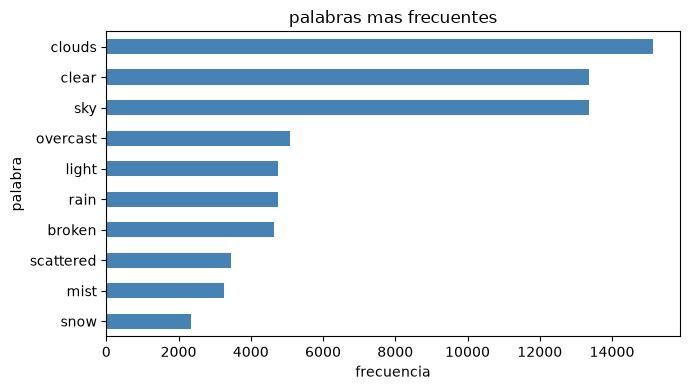

In [4]:
frecuencias.head(10).sort_values().plot.barh(figsize=(7, 4), color="steelblue")
plt.xlabel("frecuencia")
plt.ylabel("palabra")
plt.title("palabras mas frecuentes")
plt.tight_layout()
plt.show()

Nube de palabras

Las palabras mas grandes aparecen mas veces en las descripciones

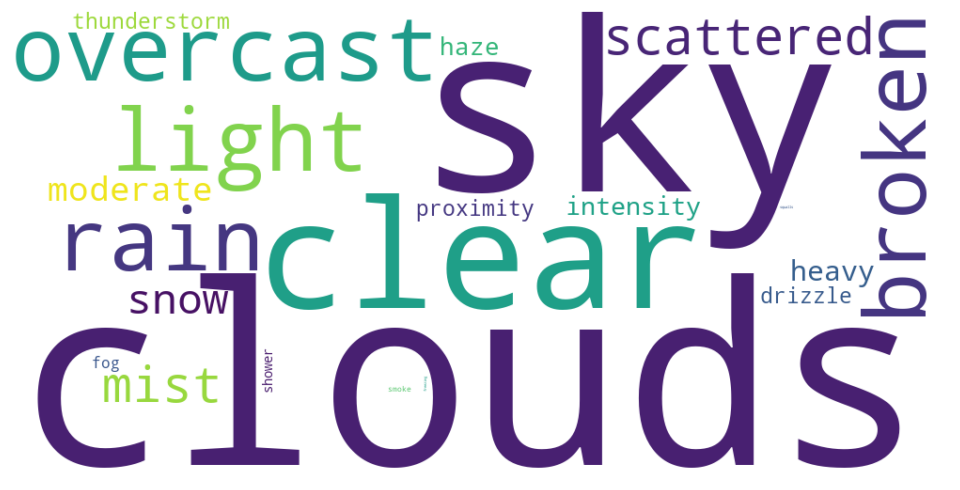

In [5]:
nube = WordCloud(
    width=1000, height=500, background_color="white",
    colormap="viridis", random_state=42
).generate_from_frequencies(frecuencias.to_dict())

plt.figure(figsize=(10, 5))
plt.imshow(nube, interpolation="bilinear")
plt.axis("off")
plt.tight_layout()
plt.show()

Clouds, sky y clear son las palabras mas frecuentes
La descripcion mas comun es sky is clear
Son textos cortos y repetidos que describen condiciones del clima